<a href="https://colab.research.google.com/github/dung-ho03/capdyssey/blob/main/(%EB%AF%B8%EC%99%84%EC%84%B1)Capdyssey_%EC%84%B8%EC%9E%90%EB%A3%8C_%EC%86%90%EB%AA%A939%EB%AA%85_10%EC%B4%88_%ED%86%B5%ED%95%A9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 세 자료 10초 통합 준비·학습
MIMIC + 6종 리듬 + 손목 v3를 공통 형식으로 준비합니다.
**현재 손목 정답 코드는 미확정이며, 6종 사용 범위 확인도 미완료입니다. 준비와 학습 완료는 다릅니다.**
손목 자료는 공식 목록의 전체 39명(001~039), ECG·PPG 78개 파일을 대상으로 합니다. 다운로드 대상 확대이며 완료 주장이 아닙니다.
미확정 정답은 -1로 보존하고 학습을 중단합니다. 설정을 True로 바꾸는 것만으로 해결되지 않습니다.
모든 다운로드·전처리·학습은 Colab 런타임에서 실행합니다. 손목 원본만 약 64GB이며 추가 전처리 공간이 필요합니다. 같은 런타임에서는 완료 파일을 검증 후 재사용하고 부분 다운로드를 이어받습니다. 런타임 삭제 시 /content 파일은 소실됩니다.
참가자별 분할, 고정 임계값 0.5, 자료별 평가를 적용합니다. 현재는 성능 결과가 없습니다.


In [ ]:
from pathlib import Path
import subprocess,sys,json
from datetime import datetime,timezone
REPO=Path('/content/capdyssey_integrated')
if not REPO.exists():
    subprocess.run(['git','clone','https://github.com/dung-ho03/capdyssey.git',str(REPO)],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(REPO/'requirements-train.txt'),'-r',str(REPO/'requirements-data.txt')],check=True)
subprocess.run(['git','-C',str(REPO),'pull','--ff-only'],check=True)
print('CODE_VERSION',subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip())

def run_logged(args):
    with subprocess.Popen(args,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1) as process:
        for line in process.stdout: print(line,end='',flush=True)
        if process.wait(): raise subprocess.CalledProcessError(process.returncode,args)


CODE_VERSION db0aeb106fc4fbdad48457a9946e1301a68fc40e


In [ ]:
run_logged([sys.executable,'-u',str(REPO/'scripts/download_data.py'),'mimic_af'])
run_logged([sys.executable,'-u',str(REPO/'scripts/download_six_for_audit.py')])
run_logged([sys.executable,'-u',str(REPO/'scripts/download_longterm_af.py'),'--all'])
print('THREE_SOURCE_DOWNLOADS_COMPLETE; wrist participants=39/39; ECG+PPG verified')


스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
015_PPG.mat 318767104 / 1074167647
015_PPG.mat 327155712 / 1074167647
015_PPG.mat 335544320 / 1074167647
015_PPG.mat 343932928 / 1074167647
015_PPG.mat 352321536 / 1074167647
015_PPG.mat 360710144 / 1074167647
015_PPG.mat 369098752 / 1074167647
015_PPG.mat 377487360 / 1074167647
015_PPG.mat 385875968 / 1074167647
015_PPG.mat 394264576 / 1074167647
015_PPG.mat 402653184 / 1074167647
015_PPG.mat 411041792 / 1074167647
015_PPG.mat 419430400 / 1074167647
015_PPG.mat 427819008 / 1074167647
015_PPG.mat 436207616 / 1074167647
015_PPG.mat 444596224 / 1074167647
015_PPG.mat 452984832 / 1074167647
015_PPG.mat 461373440 / 1074167647
015_PPG.mat 469762048 / 1074167647
015_PPG.mat 478150656 / 1074167647
015_PPG.mat 486539264 / 1074167647
015_PPG.mat 494927872 / 1074167647
015_PPG.mat 503316480 / 1074167647
015_PPG.mat 511705088 / 1074167647
015_PPG.mat 520093696 / 1074167647
015_PPG.mat 528482304 / 1074167647
015_PPG.mat 536870912 / 1074167647
015_PPG.mat 5452595

In [ ]:
BUNDLE=REPO/'data/processed'/('integrated_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
run_logged([sys.executable,'-u',str(REPO/'scripts/prepare_af_integrated.py'),
    '--mimic',str(REPO/'data/raw/mimic_af'),'--six',str(REPO/'data/raw/six_rhythms'),
    '--wrist',str(REPO/'data/raw/longterm_af_v3'),'--output',str(BUNDLE)])
manifest=json.loads((BUNDLE/'manifest.json').read_text())
summary={}
for source in manifest['sources']:
    rows=[s for s in manifest['shards'] if s['source']==source]
    summary[source]={'subjects':len({s['subject'] for s in rows}),'windows':sum(s['n'] for s in rows),
        'label_counts':{str(k):sum(s['label_counts'][str(k)] for s in rows) for k in [-1,0,1]}}
print('PREPARATION_SUMMARY',json.dumps(summary,indent=2))
assert summary['longterm_wrist_v3']['subjects']==39, 'Expected prepared windows from all 39 wrist participants'


mimic_perform_af p000946 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p075796 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p022954 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p025117 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p026377 {'-1': 0, '0': 0, '1': 107}
mimic_perform_af p043613 {'-1': 0, '0': 0, '1': 118}
mimic_perform_af p050089 {'-1': 0, '0': 0, '1': 113}
mimic_perform_af p063039 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p068956 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p069339 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p075371 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p077729 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p087275 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p079998 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p081349 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p085866 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p089565 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p092846 {'-1': 0, '0': 0, '1': 120}
mimic_perform_af p094847 {'-1': 0, '0': 0, '1'

In [ ]:
sys.path.insert(0,str(REPO/'scripts'))
from train_af_integrated import preflight
status=json.loads((REPO/'data/af_integration_status.json').read_text())
errors=preflight(manifest,status)
if errors:
    print('TRAINING_NOT_EXECUTED: unresolved requirements')
    print(chr(10).join(errors))
else:
    RUN=REPO/'runs'/('integrated_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
    subprocess.run([sys.executable,'-u',str(REPO/'scripts/train_af_integrated.py'),'--bundle',str(BUNDLE),'--output',str(RUN)],check=True)
    print((RUN/'metrics.json').read_text())


In [ ]:
subprocess.run(['git','-C',str(REPO),'pull','--ff-only'],check=True)
print('PATCH_VERSION',subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip())
import importlib
sys.path.insert(0,str(REPO/'scripts'))
import prepare_af_integrated as prep
importlib.reload(prep)
with h5py.File(REPO/'data/raw/longterm_af_v3/003_PPG.mat') as f:
    for i in range(3):
        day=prep.chars(f[f['recording_startday'][()].ravel()[i]])
        tm=prep.chars(f[f['recording_starttime'][()].ravel()[i]])
        assert prep.start_time(day,tm) is None
print('EMPTY_DATE_FIX_VERIFIED_ON_003; raw files unchanged')


PATCH_VERSION ab8e4ad4181e4affd356df24920024c36b409cf6
EMPTY_DATE_FIX_VERIFIED_ON_003; raw files unchanged


In [ ]:
from pathlib import Path
import json, shutil
r=Path('/content/capdyssey_integrated')
print('REPO_EXISTS',r.exists())
print('WRIST_FILES',len(list((r/'data/raw/longterm_af_v3').glob('*.mat'))))
print('BUNDLES',[str(p) for p in (r/'data/processed').glob('*')])
print('DRIVE_MOUNTED',Path('/content/drive/MyDrive').exists())
print('FREE_GB',round(shutil.disk_usage('/content').free/1e9,2))

REPO_EXISTS False
WRIST_FILES 0
BUNDLES []
DRIVE_MOUNTED False
FREE_GB 93.64


In [ ]:
from google.colab import drive
drive.mount('/content/drive', timeout_ms=300000)
from pathlib import Path
STORE=Path('/content/drive/MyDrive/Capdyssey/af_integrated')
STORE.mkdir(parents=True,exist_ok=True)
print('PERSISTENT_STORAGE_READY',STORE)

Mounted at /content/drive
PERSISTENT_STORAGE_READY /content/drive/MyDrive/Capdyssey/af_integrated


In [ ]:
# Drive-backed recovery: validate, download all 39, prepare, then check training readiness.
from pathlib import Path
import subprocess, sys, json
REPO=Path('/content/capdyssey_integrated')
assert Path('/content/drive/MyDrive').is_dir(), 'Connect Google Drive first'
if not REPO.exists():
    subprocess.run(['git','clone','https://github.com/dung-ho03/capdyssey.git',str(REPO)],check=True)
subprocess.run(['git','-C',str(REPO),'pull','--ff-only'],check=True)
recovery_nb=json.loads((REPO/'notebooks/04_af_integrated_colab.ipynb').read_text())
exec(compile(''.join(recovery_nb['cells'][1]['source']),'drive_setup','exec'))
run_logged([sys.executable,'-m','unittest','discover','-s',str(REPO/'tests'),'-p','test_integrated_data.py'])
print('COLAB_RESUME_TESTS_PASSED',flush=True)
for recovery_stage in (2,3,4):
    print('RECOVERY_STAGE',recovery_stage,flush=True)
    exec(compile(''.join(recovery_nb['cells'][recovery_stage]['source']),f'recovery_stage_{recovery_stage}','exec'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CODE_VERSION 73c3bde1fd77fbf83a2f9b393a8e2ec49f51d3e5
PERSISTENT_STORAGE_READY /content/drive/MyDrive/Capdyssey/af_integrated
.....
----------------------------------------------------------------------
Ran 5 tests in 0.007s

OK
COLAB_RESUME_TESTS_PASSED
RECOVERY_STAGE 2
mimic_af: MIMIC PERform AF | ODbL-1.0; AF annotations CC-BY-4.0
https://zenodo.org/records/15906524
mimic_af: complete, 2 verified files
Verified MPA_181220181216.mat
Verified MPA_181221154421.mat
Verified MPA_181221201409.mat
Verified MPA_190103190940.mat
Verified MPA_190110210436.mat
Verified MPA_190104135702.mat
Verified MPA_190103210456.mat
Verified MPA_190111175619.mat
Verified MPA_190111200054.mat
Verified MPA_190111161158.mat
Verified MPA_190117165510.mat
Verified MPA_190117213615.mat
Verified MPA_190118201237.mat
Verified MPA_190117190002.mat
Verified MPA_190123210803.mat
Verified MPA

CalledProcessError: Command '['/usr/bin/python3', '-u', '/content/capdyssey_integrated/scripts/download_longterm_af.py', '--all']' returned non-zero exit status 1.

In [ ]:
# Repair Drive download integrity: use runtime-local staging per file.
subprocess.run(['git','-C',str(REPO),'pull','--ff-only'],check=True)
print('DOWNLOAD_FIX_VERSION',subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip())
run_logged([sys.executable,'-m','unittest','discover','-s',str(REPO/'tests'),'-p','test_download_longterm_af.py'])
print('COLAB_DOWNLOAD_TESTS_PASSED',flush=True)
run_logged([sys.executable,'-u',str(REPO/'scripts/download_longterm_af.py'),'--all'])
print('WRIST_39_DOWNLOADS_PERSISTED_AND_VERIFIED',flush=True)
recovery_nb=json.loads((REPO/'notebooks/04_af_integrated_colab.ipynb').read_text())
for recovery_stage in (3,4):
    print('RECOVERY_STAGE',recovery_stage,flush=True)
    exec(compile(''.join(recovery_nb['cells'][recovery_stage]['source']),f'recovery_stage_{recovery_stage}','exec'))

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
018_PPG.mat 201326592 / 1343330864
018_PPG.mat 209715200 / 1343330864
018_PPG.mat 218103808 / 1343330864
018_PPG.mat 226492416 / 1343330864
018_PPG.mat 234881024 / 1343330864
018_PPG.mat 243269632 / 1343330864
018_PPG.mat 251658240 / 1343330864
018_PPG.mat 260046848 / 1343330864
018_PPG.mat 268435456 / 1343330864
018_PPG.mat 276824064 / 1343330864
018_PPG.mat 285212672 / 1343330864
018_PPG.mat 293601280 / 1343330864
018_PPG.mat 301989888 / 1343330864
018_PPG.mat 310378496 / 1343330864
018_PPG.mat 318767104 / 1343330864
018_PPG.mat 327155712 / 1343330864
018_PPG.mat 335544320 / 1343330864
018_PPG.mat 343932928 / 1343330864
018_PPG.mat 352321536 / 1343330864
018_PPG.mat 360710144 / 1343330864
018_PPG.mat 369098752 / 1343330864
018_PPG.mat 377487360 / 1343330864
018_PPG.mat 385875968 / 1343330864
018_PPG.mat 394264576 / 1343330864
018_PPG.mat 402653184 / 1343330864
018_PPG.mat 411041792 / 1343330864
018_PPG.mat 419430400 / 1343330864
018_PPG.mat 4278190

AssertionError: Expected prepared windows from all 39 wrist participants

In [ ]:
# Audit missing participants without downloading or repeating preprocessing.
import h5py, numpy as np
sys.path.insert(0,str(REPO/'scripts'))
from prepare_af_integrated import chars,start_time
manifest=json.loads((BUNDLE/'manifest.json').read_text())
raw=REPO/'data/raw/longterm_af_v3'
expected={f'{i:03d}' for i in range(1,40)}
prepared={s['subject'].split(':')[-1] for s in manifest['shards'] if s['source']=='longterm_wrist_v3'}
missing=sorted(expected-prepared)
print('RAW_PAIRS',sum((raw/f'{p}_ECG.mat').exists() and (raw/f'{p}_PPG.mat').exists() for p in expected))
print('MISSING_PREPARED',missing)
for person in missing:
    with h5py.File(raw/f'{person}_ECG.mat') as e,h5py.File(raw/f'{person}_PPG.mat') as p:
        es=start_time(chars(e['recording_startday']),chars(e['recording_starttime']))
        ee=es+e['ECG'].size/500
        print('ECG',person,'start',es,'end',ee,'shape',e['ECG'].shape)
        for i,ref in enumerate(p['PPG_GREEN'][()].ravel()):
            day=chars(p[p['recording_startday'][()].ravel()[i]])
            tm=chars(p[p['recording_starttime'][()].ravel()[i]])
            ps=start_time(day,tm);seconds=p[ref].size/100
            print('PPG',person,i,'day',repr(day),'time',repr(tm),'seconds',seconds,'overlap_seconds',None if ps is None else max(0,min(ps+seconds,ee)-max(ps,es)))


RAW_PAIRS 39
MISSING_PREPARED ['025', '035']
ECG 025 start 49682 end 647054.0 shape (298686000, 1)
PPG 025 0 day '01' time '13:38:19' seconds 24832.0 overlap_seconds 24249.0
PPG 025 1 day '01' time '22:11:29' seconds 30443.99 overlap_seconds 30443.990000000005
PPG 025 2 day '02' time '06:39:06' seconds 50105.99 overlap_seconds 50105.98999999999
PPG 025 3 day '02' time '22:17:10' seconds 49510.98 overlap_seconds 49510.98000000001
PPG 025 4 day '03' time '12:02:41' seconds 30197.0 overlap_seconds 30197.0
PPG 025 5 day '03' time '21:59:19' seconds 81247.99 overlap_seconds 81247.98999999999
PPG 025 6 day '04' time '22:08:37' seconds 80459.0 overlap_seconds 80459.0
PPG 025 7 day '05' time '22:11:52' seconds 11795.0 overlap_seconds 11795.0
PPG 025 8 day '06' time '01:28:45' seconds 6205.0 overlap_seconds 6205.0
PPG 025 9 day '06' time '03:12:24' seconds 62821.99 overlap_seconds 62821.98999999999
PPG 025 10 day '06' time '22:09:33' seconds 53487.99 overlap_seconds 53487.98999999999
PPG 025 11

In [ ]:
# Full-record basic quality counts for the two missing participants.
quality_audit=[]
for person in missing:
    with h5py.File(raw/f'{person}_PPG.mat') as p:
        for i,ref in enumerate(p['PPG_GREEN'][()].ravel()):
            v=np.asarray(p[ref][()]).ravel(); n=len(v)//1000
            w=v[:n*1000].reshape(n,1000).astype(np.float64)
            finite=np.isfinite(w).all(axis=1)
            sd=np.std(w[finite],axis=1)
            row={'subject':person,'record':i,'dtype':str(v.dtype),'windows':n,'nonfinite':int((~finite).sum()),'flat':int((sd<1e-8).sum()),'basic_valid':int((sd>=1e-8).sum()),'max_std':float(sd.max()) if len(sd) else None}
            quality_audit.append(row); print(row,flush=True)
            del v,w
(BUNDLE/'missing_subject_quality_audit.json').write_text(json.dumps(quality_audit,indent=2))
print('QUALITY_AUDIT_SAVED')

{'subject': '025', 'record': 0, 'dtype': 'float64', 'windows': 2483, 'nonfinite': 0, 'flat': 2483, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 1, 'dtype': 'float64', 'windows': 3044, 'nonfinite': 0, 'flat': 3044, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 2, 'dtype': 'float64', 'windows': 5010, 'nonfinite': 0, 'flat': 5010, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 3, 'dtype': 'float64', 'windows': 4951, 'nonfinite': 0, 'flat': 4951, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 4, 'dtype': 'float64', 'windows': 3019, 'nonfinite': 0, 'flat': 3019, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 5, 'dtype': 'float64', 'windows': 8124, 'nonfinite': 0, 'flat': 8124, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 6, 'dtype': 'float64', 'windows': 8045, 'nonfinite': 0, 'flat': 8045, 'basic_valid': 0, 'max_std': 0.0}
{'subject': '025', 'record': 7, 'dtype': 'float64', 'windows': 1179, 

In [ ]:
# Complete coverage accounting using already saved preprocessing; no rerun.
assert len(expected)==39
assert all((raw/f'{p}_ECG.mat').is_file() and (raw/f'{p}_PPG.mat').is_file() for p in expected)
assert {r['subject'] for r in quality_audit}==set(missing)
assert all(r['basic_valid']==0 and r['flat']==r['windows'] and r['max_std']==0 for r in quality_audit)
coverage={'raw_participants':39,'prepared_participants':len(prepared),'without_valid_windows':missing,'reason':'All complete 10-second GREEN windows have zero standard deviation in excluded participants'}
(BUNDLE/'cohort_coverage.json').write_text(json.dumps(coverage,indent=2))
print('PREPROCESSING_COMPLETE_WITH_DOCUMENTED_EXCLUSIONS')
print(json.dumps(coverage,indent=2))
print('SAVED_BUNDLE',BUNDLE)
exec(compile(''.join(recovery_nb['cells'][4]['source']),'training_readiness','exec'))

PREPROCESSING_COMPLETE_WITH_DOCUMENTED_EXCLUSIONS
{
  "raw_participants": 39,
  "prepared_participants": 37,
  "without_valid_windows": [
    "025",
    "035"
  ],
  "reason": "All complete 10-second GREEN windows have zero standard deviation in excluded participants"
}
SAVED_BUNDLE /content/drive/MyDrive/Capdyssey/af_integrated/processed/integrated_10s_resume_v1
TRAINING_NOT_EXECUTED: unresolved requirements
longterm_wrist_v3: Numeric label definitions and QRS/RR annotation alignment not confirmed; acquisition target expanded to all 39, completion must be verified in Colab
longterm_wrist_v3: unresolved labels remain
six_rhythms: Research citation invitation verified; explicit training/derived-sharing scope remains unresolved in stage 1


In [ ]:
# Inspect annotation metadata only; no label guessing or waveform retraining.
import h5py, numpy as np, json
from pathlib import Path
raw=Path('/content/drive/MyDrive/Capdyssey/af_integrated/raw/longterm_af_v3')
for person in ('001','006','039'):
    with h5py.File(raw/f'{person}_ECG.mat') as f:
        print('SUBJECT',person,'ROOT_KEYS',list(f.keys()))
        for key in f:
            if key.startswith('#'): continue
            d=f[key]
            print('FIELD',key,'shape',getattr(d,'shape',None),'attrs',{k:str(v) for k,v in d.attrs.items()})
            if isinstance(d,h5py.Dataset) and d.size<500:
                print('SMALL_VALUE',key,str(d[()])[:2500])
        print('ANNOTATION_FIRST_30',f['AF_annotation'][()].ravel()[:30])
print('ANNOTATION_METADATA_INSPECTION_COMPLETE')

SUBJECT 001 ROOT_KEYS ['#refs#', 'AF_annotation', 'Accelerometer_X', 'Accelerometer_Y', 'Accelerometer_Z', 'ECG', 'QRSindex', 'recording_startday', 'recording_starttime', 'rr', 'signalHeader']
FIELD AF_annotation shape (900420, 1) attrs {'MATLAB_class': "b'double'"}
FIELD Accelerometer_X shape (16503200, 1) attrs {'MATLAB_class': "b'double'"}
FIELD Accelerometer_Y shape (16503200, 1) attrs {'MATLAB_class': "b'double'"}
FIELD Accelerometer_Z shape (16503200, 1) attrs {'MATLAB_class': "b'double'"}
FIELD ECG shape (330064000, 1) attrs {'MATLAB_class': "b'double'"}
FIELD QRSindex shape (900421, 1) attrs {'MATLAB_class': "b'double'"}
FIELD recording_startday shape (2, 1) attrs {'MATLAB_class': "b'char'", 'MATLAB_int_decode': '2'}
SMALL_VALUE recording_startday [[48]
 [49]]
FIELD recording_starttime shape (8, 1) attrs {'MATLAB_class': "b'char'", 'MATLAB_int_decode': '2'}
SMALL_VALUE recording_starttime [[49]
 [55]
 [58]
 [53]
 [56]
 [58]
 [53]
 [53]]
FIELD rr shape (900420, 1) attrs {'MATLAB

In [ ]:
subprocess.run(['git','-C',str(REPO),'pull','--ff-only'],check=True)
run_logged([sys.executable,'-u',str(REPO/'scripts/audit_wrist_annotations.py'),'--raw',str(raw),'--output',str(BUNDLE/'annotation_audit_39.json')])
audit39=json.loads((BUNDLE/'annotation_audit_39.json').read_text())
print('AUDIT_SUMMARY',json.dumps({'participants':audit39['participants'],'codes':sorted({k for r in audit39['subjects'] for k in r['annotation_counts']}),'length_failures':[r['subject'] for r in audit39['subjects'] if not r['lengths_match']],'qrs_order_failures':[r['subject'] for r in audit39['subjects'] if not r['qrs_strictly_increasing']],'max_rr_error':max(r['rr_vs_qrs_seconds_max_error'] or 0 for r in audit39['subjects'])},indent=2))

{"subject": "001", "annotation_counts": {"0.0": 626188, "1.0": 274232}, "annotation_rr_qrs_lengths": [900420, 900420, 900421], "lengths_match": true, "all_finite": true, "qrs_strictly_increasing": true, "rr_vs_qrs_seconds_max_error": 2.842170943040401e-14, "qrs_within_ecg_1_based": true, "annotation_attrs": {"MATLAB_class": "b'double'"}}
{"subject": "002", "annotation_counts": {"0.0": 605251, "1.0": 23486}, "annotation_rr_qrs_lengths": [628737, 628737, 628738], "lengths_match": true, "all_finite": true, "qrs_strictly_increasing": true, "rr_vs_qrs_seconds_max_error": 2.842170943040401e-14, "qrs_within_ecg_1_based": true, "annotation_attrs": {"MATLAB_class": "b'double'"}}
{"subject": "003", "annotation_counts": {"0.0": 419022, "0.5": 9, "1.0": 281315}, "annotation_rr_qrs_lengths": [700346, 700346, 700347], "lengths_match": true, "all_finite": true, "qrs_strictly_increasing": true, "rr_vs_qrs_seconds_max_error": 7.105427357601002e-15, "qrs_within_ecg_1_based": false, "annotation_attrs": {

In [ ]:
# Read-only source audit: official versions, workbook notes, MAT metadata.
from pathlib import Path
import json, re, zipfile, io, requests, xml.etree.ElementTree as ET
RAW_AUDIT = Path('/content/drive/MyDrive/Capdyssey/af_integrated/raw/longterm_af_v3')
AUDIT_OUT = Path('/content/drive/MyDrive/Capdyssey/af_integrated/processed/integrated_10s_resume_v1')
source_audit = {'versions': [], 'workbooks': []}
for record in ['23187681','11242869','5815074']:
    try:
        res = requests.get('https://zenodo.org/api/records/'+record, timeout=30)
        res.raise_for_status()
        rec = res.json()
        desc = rec['metadata'].get('description','')
        files = rec.get('files',[])
        item = {'record':record,'description':desc,'related_identifiers':rec['metadata'].get('related_identifiers',[]),'files':[f['key'] for f in files]}
        source_audit['versions'].append(item)
        print('VERSION', record, 'FILES', item['files'], 'RELATED', item['related_identifiers'], flush=True)
        print('DESCRIPTION', re.sub('<[^>]+>',' ',desc), flush=True)
        for entry in files:
            if not entry['key'].lower().endswith('.xlsx'): continue
            local = RAW_AUDIT/entry['key']
            data = local.read_bytes() if record=='23187681' and local.exists() else requests.get(entry['links']['self'],timeout=30).content
            with zipfile.ZipFile(io.BytesIO(data)) as z:
                ns = {'s':'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
                workbook = ET.fromstring(z.read('xl/workbook.xml'))
                sheets = [dict(n.attrib) for n in workbook.findall('s:sheets/s:sheet', ns)]
                strings=[]
                for name in z.namelist():
                    if name.endswith('.xml') and (name.startswith('xl/') or name.startswith('docProps/')):
                        root = ET.fromstring(z.read(name))
                        values = [n.text for n in root.iter() if n.text and n.text.strip() and not re.fullmatch(r'[-+0-9., :/]+',n.text.strip())]
                        strings.extend((name,v) for v in values)
                unique = sorted(set(strings))
                wb = {'record':record,'filename':entry['key'],'sheets':sheets,'xml_parts':z.namelist(),'text_entries':unique}
                source_audit['workbooks'].append(wb)
                print('WORKBOOK_ALL_TEXT', json.dumps(wb,ensure_ascii=False), flush=True)
    except Exception as e:
        print('SOURCE_AUDIT_ERROR',record,type(e).__name__,str(e),flush=True)
AUDIT_OUT.mkdir(parents=True,exist_ok=True)
(AUDIT_OUT/'source_document_audit.json').write_text(json.dumps(source_audit,ensure_ascii=False,indent=2))
print('SOURCE_DOCUMENT_AUDIT_COMPLETE',flush=True)


VERSION 23187681 FILES ['016_PPG.mat', '015_PPG.mat', '014_PPG.mat', '012_ECG.mat', '032_ECG.mat', '007_PPG.mat', '011_ECG.mat', '026_ECG.mat', '026_PPG.mat', '025_ECG.mat', '025_PPG.mat', '010_PPG.mat', '027_ECG.mat', 'subject_info.xlsx', '003_ECG.mat', '002_ECG.mat', '004_ECG.mat', 'LICENSE.txt', '001_ECG.mat', '027_PPG.mat', '001_PPG.mat', '004_PPG.mat', '007_ECG.mat', '006_PPG.mat', '005_ECG.mat', '005_PPG.mat', '031_ECG.mat', '028_PPG.mat', '002_PPG.mat', '003_PPG.mat', '028_ECG.mat', '006_ECG.mat', '008_ECG.mat', '008_PPG.mat', '029_ECG.mat', '030_ECG.mat', '011_PPG.mat', '010_ECG.mat', '030_PPG.mat', '032_PPG.mat', '029_PPG.mat', '031_PPG.mat', '012_PPG.mat', '013_ECG.mat', '013_PPG.mat', '014_ECG.mat', '039_PPG.mat', '033_PPG.mat', '016_ECG.mat', '033_ECG.mat', '015_ECG.mat', '034_ECG.mat', '035_PPG.mat', '034_PPG.mat', '036_ECG.mat', '037_PPG.mat', '019_ECG.mat', '038_ECG.mat', '018_ECG.mat', '019_PPG.mat', '038_PPG.mat', '039_ECG.mat', '009_ECG.mat', '020_ECG.mat', '009_PPG.m

In [ ]:
import h5py, numpy as np
from collections import Counter
mat_audit = []
all_text = {}
for file in sorted(RAW_AUDIT.glob('*.mat')):
    row={'file':file.name,'texts':[],'attributes':[],'keys':[],'errors':[]}
    try:
        with file.open('rb') as fh:
            row['mat_header']=fh.read(116).decode('ascii',errors='replace')
        with h5py.File(file,'r') as hf:
            row['root_attributes']={k:str(v) for k,v in hf.attrs.items()}
            def visit(name,obj):
                row['keys'].append(name)
                for key,value in obj.attrs.items():
                    if key not in ['MATLAB_class','MATLAB_fields','MATLAB_int_decode','H5PATH','MATLAB_empty']:
                        row['attributes'].append([name,key,str(value)])
                if isinstance(obj,h5py.Dataset):
                    cls=obj.attrs.get('MATLAB_class',b'')
                    if cls in [b'char','char']:
                        text=''.join(chr(int(x)) for x in np.asarray(obj).ravel(order='F') if int(x)>0)
                        row['texts'].append([name,text])
                        all_text.setdefault(text,[]).append(file.name+':'+name)
                    elif obj.dtype.kind in ['S','U']:
                        text=str(obj[()])
                        row['texts'].append([name,text])
                        all_text.setdefault(text,[]).append(file.name+':'+name)
            hf.visititems(visit)
    except Exception as e:
        row['errors'].append(type(e).__name__+':'+str(e))
    mat_audit.append(row)
    print('MAT_METADATA',file.name,'objects',len(row['keys']),'text_fields',len(row['texts']),'extra_attributes',len(row['attributes']),'errors',row['errors'],flush=True)
(AUDIT_OUT/'mat_metadata_audit_78.json').write_text(json.dumps(mat_audit,ensure_ascii=False,indent=2))
print('ALL_MEANINGFUL_MAT_TEXT',json.dumps({k:v[:3] for k,v in all_text.items() if re.search('[A-Za-z]',k)},ensure_ascii=False))
print('EXTRA_ATTRIBUTES',json.dumps([{'file':r['file'],'root':r.get('root_attributes',{}),'attrs':r['attributes']} for r in mat_audit if r.get('root_attributes') or r['attributes']],ensure_ascii=False))
print('MAT_METADATA_AUDIT_COMPLETE',len(mat_audit),'files; errors',sum(bool(r['errors']) for r in mat_audit),flush=True)


MAT_METADATA 001_ECG.mat objects 37 text_fields 10 extra_attributes 0 errors []
MAT_METADATA 001_PPG.mat objects 131 text_fields 36 extra_attributes 0 errors []
MAT_METADATA 002_ECG.mat objects 37 text_fields 10 extra_attributes 0 errors []
MAT_METADATA 002_PPG.mat objects 124 text_fields 34 extra_attributes 0 errors []
MAT_METADATA 003_ECG.mat objects 37 text_fields 10 extra_attributes 0 errors []
MAT_METADATA 003_PPG.mat objects 124 text_fields 34 extra_attributes 0 errors []
MAT_METADATA 004_ECG.mat objects 37 text_fields 10 extra_attributes 0 errors []
MAT_METADATA 004_PPG.mat objects 159 text_fields 44 extra_attributes 0 errors []
MAT_METADATA 005_ECG.mat objects 37 text_fields 10 extra_attributes 0 errors []
MAT_METADATA 005_PPG.mat objects 82 text_fields 22 extra_attributes 0 errors []
MAT_METADATA 006_ECG.mat objects 37 text_fields 10 extra_attributes 0 errors []
MAT_METADATA 006_PPG.mat objects 68 text_fields 18 extra_attributes 0 errors []
MAT_METADATA 007_ECG.mat objects 37 

In [ ]:
from pathlib import Path
import json
verified_out = Path('/content/drive/MyDrive/Capdyssey/af_integrated/processed/integrated_10s_resume_v1')
for name in ['source_document_audit.json', 'mat_metadata_audit_78.json']:
    p = verified_out / name
    assert p.is_file(), str(p)
    print('DRIVE_REPORT_SAVED', name, p.stat().st_size, 'bytes')
saved_mat = json.loads((verified_out/'mat_metadata_audit_78.json').read_text())
assert len(saved_mat) == 78
assert not any(r['errors'] for r in saved_mat)
print('RESULT: 39 subjects / 78 MAT files inspected; errors=0')
print('No rhythm-code legend found in text datasets or extra attributes.')
print('AF_annotation values remain unmapped: 0, 0.25, 0.5, 1')
print('No labels changed. Integrated training has not started.')
print('Reports:', verified_out)


DRIVE_REPORT_SAVED source_document_audit.json 32691 bytes
DRIVE_REPORT_SAVED mat_metadata_audit_78.json 245446 bytes
RESULT: 39 subjects / 78 MAT files inspected; errors=0
No rhythm-code legend found in text datasets or extra attributes.
AF_annotation values remain unmapped: 0, 0.25, 0.5, 1
No labels changed. Integrated training has not started.
Reports: /content/drive/MyDrive/Capdyssey/af_integrated/processed/integrated_10s_resume_v1


In [ ]:
from google.colab import drive
from pathlib import Path
if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive', timeout_ms=300000)
print('DRIVE_READY', Path('/content/drive/MyDrive/Capdyssey/af_integrated').exists())


Mounted at /content/drive
DRIVE_READY True


In [ ]:
import subprocess, sys, json
from pathlib import Path
repo = Path('/content/capdyssey_provisional')
if not repo.exists():
    subprocess.run(['git','clone','https://github.com/dung-ho03/capdyssey.git',str(repo)],check=True)
subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-p','test_provisional_labels.py'],cwd=repo,check=True)
base=Path('/content/drive/MyDrive/Capdyssey/af_integrated')
bundle=base/'processed/provisional_exact01_v1'
print('PREPARED_EXISTS', (base/'processed/integrated_10s_resume_v1/manifest.json').exists())
print('WRIST_ECG_FILES',len(list((base/'raw/longterm_af_v3').glob('*_ECG.mat'))))
import torch
print('DEVICE', 'cuda' if torch.cuda.is_available() else 'Colab CPU')


PREPARED_EXISTS True
WRIST_ECG_FILES 39
DEVICE Colab CPU


In [ ]:
# 잠정 실험: 정확한 원본 0/1만 사용, 분수 값과 전환 경계 제외
import shutil, os
shutil.copy2(repo/'notebooks/05_af_provisional_colab.ipynb',base/'05_af_provisional_colab.ipynb')
log_path=base/'provisional_exact01_v1.log'
def run_logged(args):
    with log_path.open('a') as log:
        process=subprocess.Popen([sys.executable,'-u',*args],cwd=repo,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,env={**os.environ,'OMP_NUM_THREADS':'2','MKL_NUM_THREADS':'2'})
        for line in process.stdout:
            print(line,end='',flush=True); log.write(line); log.flush()
        if process.wait(): raise RuntimeError('실행 실패: 위 로그 확인')
if not (bundle/'manifest.json').exists():
    run_logged(['scripts/prepare_af_provisional.py','--bundle',str(base/'processed/integrated_10s_resume_v1'),'--wrist',str(base/'raw/longterm_af_v3'),'--output',str(bundle)])
print('PREPARATION_COMPLETE: starting provisional training',flush=True)
run_logged(['scripts/train_af_integrated.py','--bundle',str(bundle),'--output',str(base/'models/provisional_exact01_v1'),'--epochs','20','--provisional'])
print('PROVISIONAL_EXPERIMENT_COMPLETE',flush=True)


longterm_wrist_v3:001 eligible {0: 48663, 1: 13203} selected 4000
longterm_wrist_v3:002 eligible {0: 49958, 1: 1367} selected 3367
longterm_wrist_v3:004 eligible {0: 56858, 1: 17} selected 2017
longterm_wrist_v3:005 eligible {0: 28607, 1: 4032} selected 4000
longterm_wrist_v3:006 eligible {0: 2116, 1: 1049} selected 3049
longterm_wrist_v3:007 eligible {0: 35082, 1: 2} selected 2002
longterm_wrist_v3:008 eligible {0: 34445, 1: 127} selected 2127
longterm_wrist_v3:009 eligible {0: 28480, 1: 510} selected 2510
longterm_wrist_v3:010 eligible {0: 37404, 1: 10581} selected 4000
longterm_wrist_v3:011 eligible {0: 54412, 1: 38} selected 2038
longterm_wrist_v3:012 eligible {0: 60667, 1: 0} selected 2000
longterm_wrist_v3:013 eligible {0: 16081, 1: 2842} selected 4000
longterm_wrist_v3:014 eligible {0: 24116, 1: 7415} selected 4000
longterm_wrist_v3:015 eligible {0: 32937, 1: 3382} selected 4000
longterm_wrist_v3:016 eligible {0: 2638, 1: 31914} selected 4000
longterm_wrist_v3:017 eligible {0: 4

METRICS_REPRODUCED {"longterm_wrist_v3": {"threshold": 0.5, "n": 23051, "tp": 2227, "fn": 6824, "tn": 9065, "fp": 4935, "accuracy": 0.4898702876230966, "sensitivity": 0.24605016020329246, "specificity": 0.6475, "false_positive_rate": 0.3525, "balanced_accuracy": 0.44677508010164624, "f1": 0.2747178190341084, "roc_auc": 0.4481835590384646}, "mimic_perform_af": {"threshold": 0.5, "n": 776, "tp": 402, "fn": 71, "tn": 267, "fp": 36, "accuracy": 0.8621134020618557, "sensitivity": 0.8498942917547568, "specificity": 0.8811881188118812, "false_positive_rate": 0.1188118811881188, "balanced_accuracy": 0.865541205283319, "f1": 0.8825466520307355, "roc_auc": 0.9563421458424912}, "six_rhythms": {"threshold": 0.5, "n": 8814, "tp": 2094, "fn": 659, "tn": 5765, "fp": 296, "accuracy": 0.8916496482868165, "sensitivity": 0.7606247729749365, "specificity": 0.9511631743936644, "false_positive_rate": 0.048836825606335586, "balanced_accuracy": 0.8558939736843004, "f1": 0.8143107135912891, "roc_auc": 0.958203

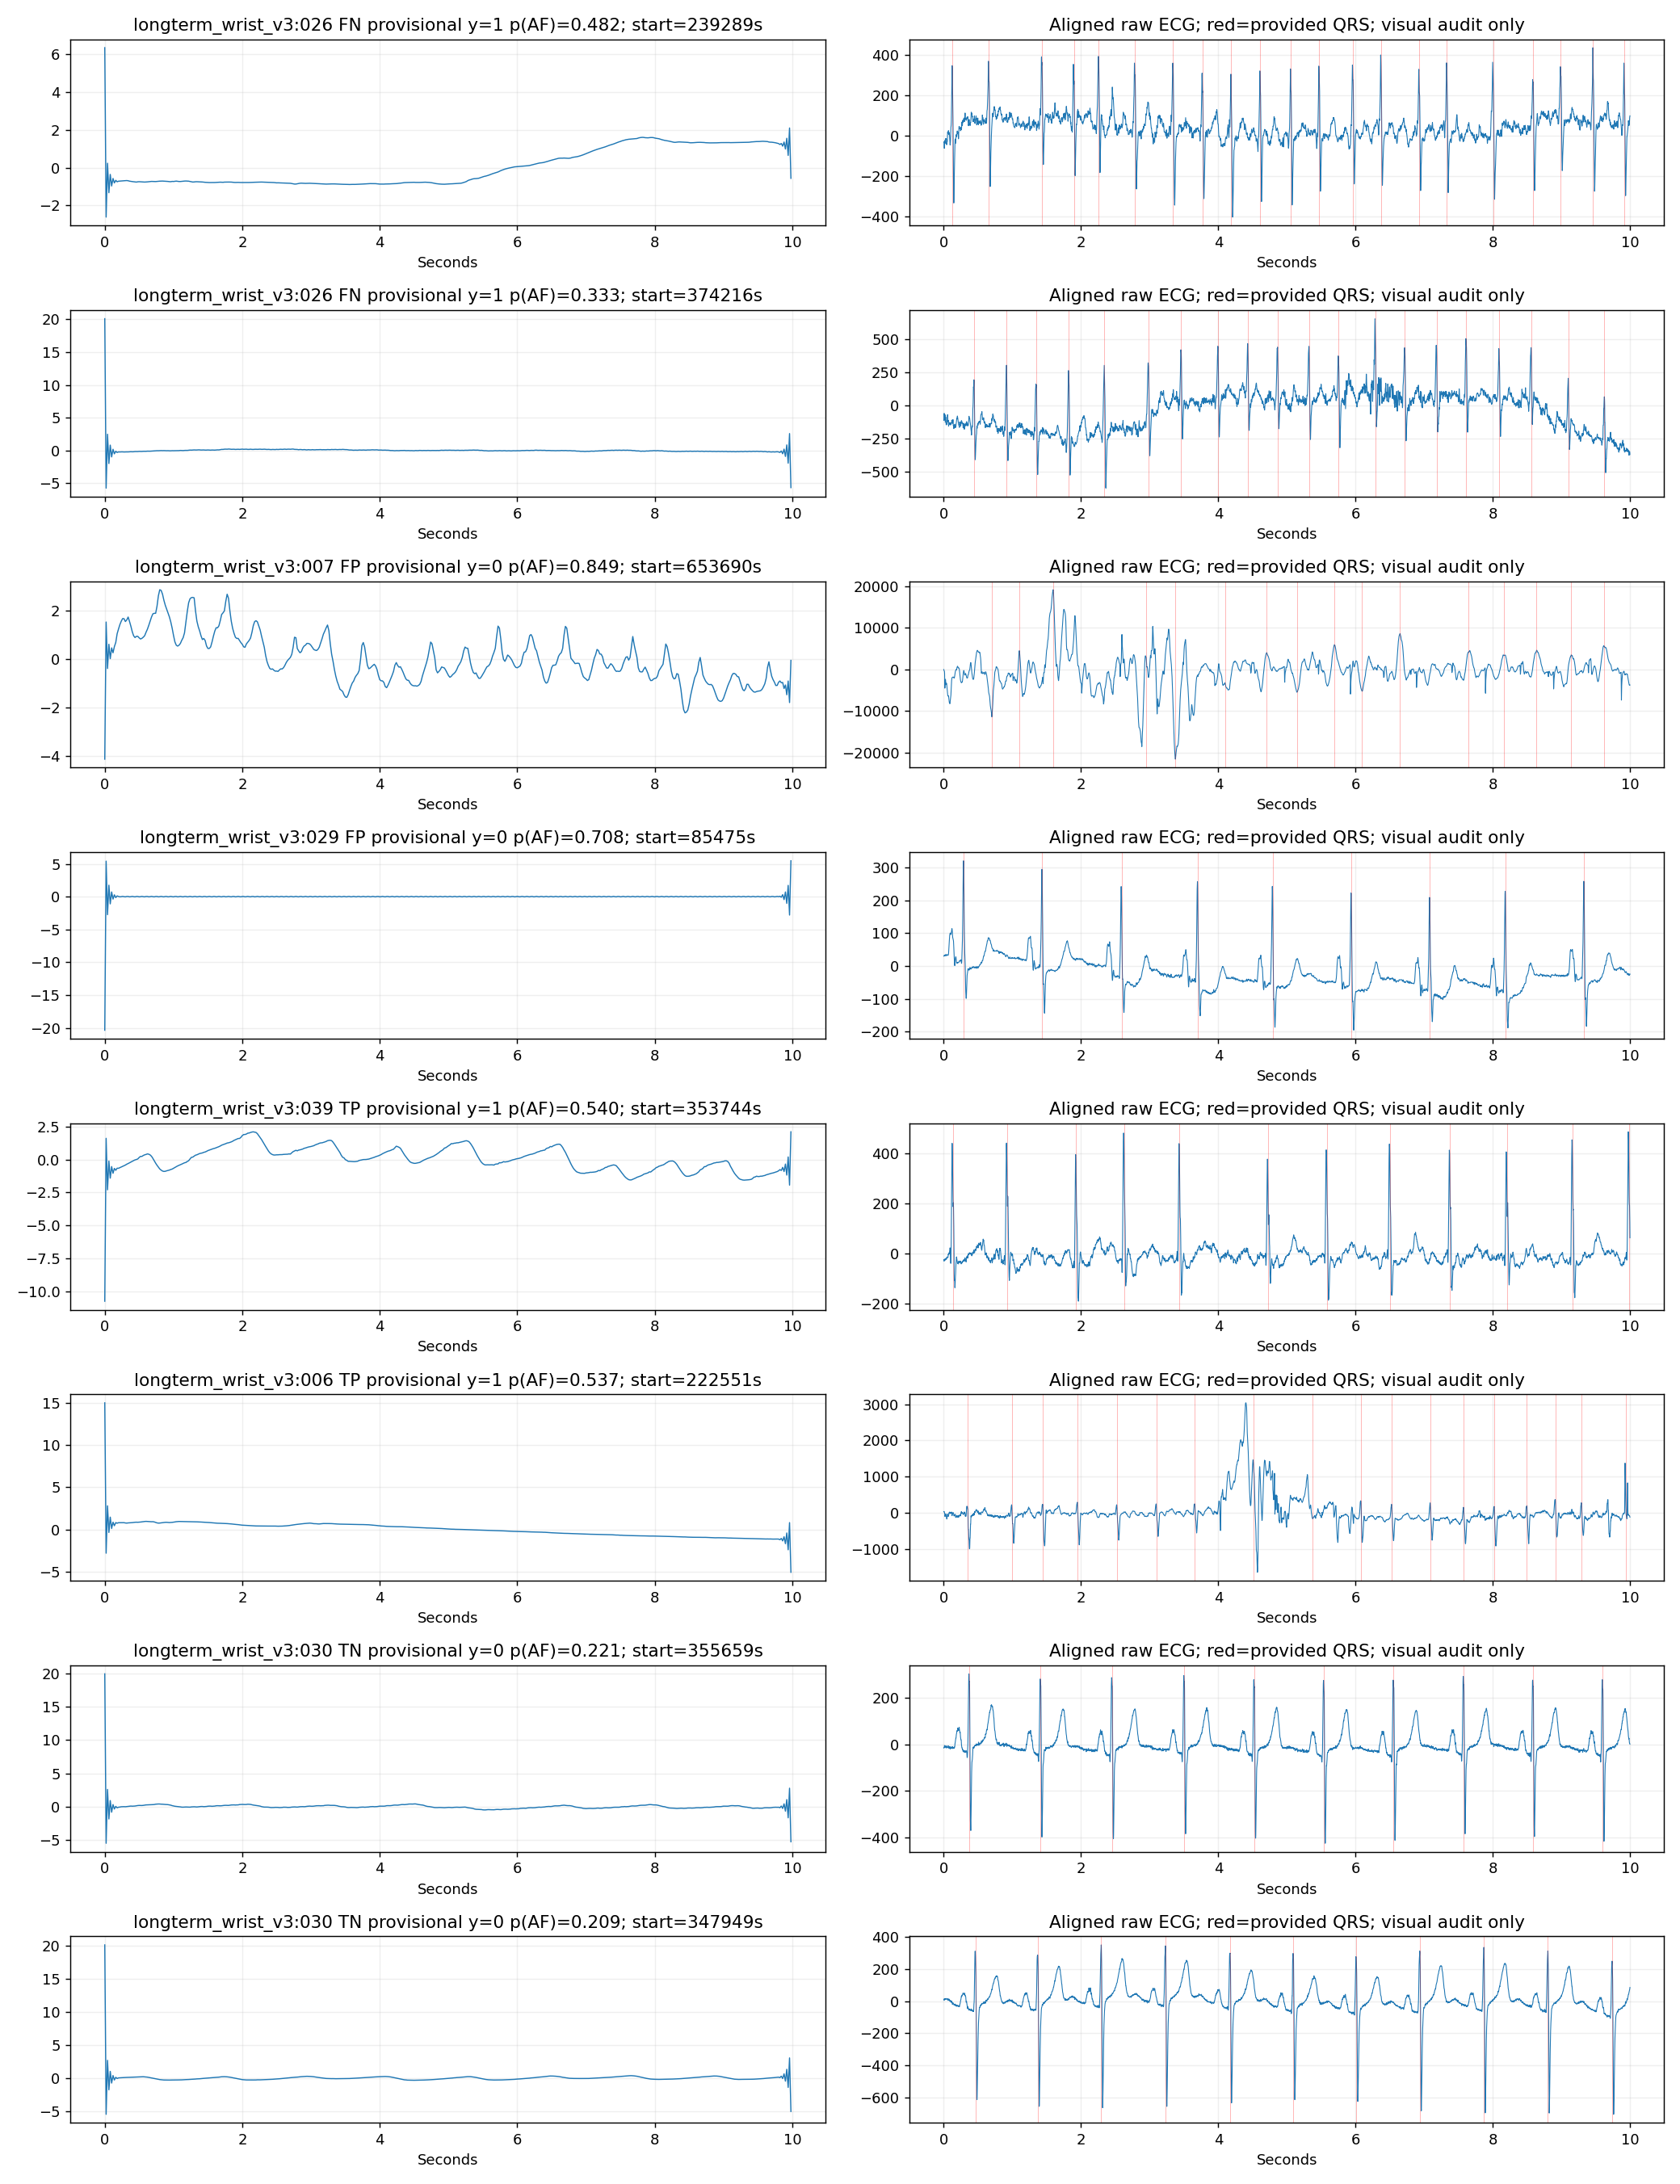

In [ ]:
# 고정된 8회차 모델의 오분류 점검. 재학습/정답변경 없음.
subprocess.run(['git','pull','--ff-only'],cwd=repo,check=True)
run_logged(['scripts/audit_af_errors.py','--base',str(base)])
from IPython.display import display, Image
display(Image(filename=str(base/'models/provisional_exact01_v1/error_audit_v1/ppg_ecg_examples.png')))


RAW_BOUNDARY_CHECK [{"subject": "026", "outcome": "FN", "record": "026_004", "raw_mean": -953751.6021383447, "raw_std": 32876.91587288695, "raw_dc_to_std": 29.009764961709436, "stored_reproduction_max_error": 0.0, "original_peak_index": 0, "original_edge_energy_fraction": 0.1370021402835846, "centered_edge_energy_fraction": 0.04490826534956003, "original_peak_z": 6.350193500518799, "centered_peak_z": 1.6963353490023494}, {"subject": "026", "outcome": "FN", "record": "026_006", "raw_mean": -990206.0129311262, "raw_std": 1437.6768847130088, "raw_dc_to_std": 688.7542141493028, "stored_reproduction_max_error": 0.0, "original_peak_index": 0, "original_edge_energy_fraction": 0.9878544807434082, "centered_edge_energy_fraction": 0.1391632755967218, "original_peak_z": 20.09661102294922, "centered_peak_z": 2.5148058564876035}, {"subject": "007", "outcome": "FP", "record": "007_012", "raw_mean": 524352.630316638, "raw_std": 28953.452516240555, "raw_dc_to_std": 18.110193595134067, "stored_reproduc

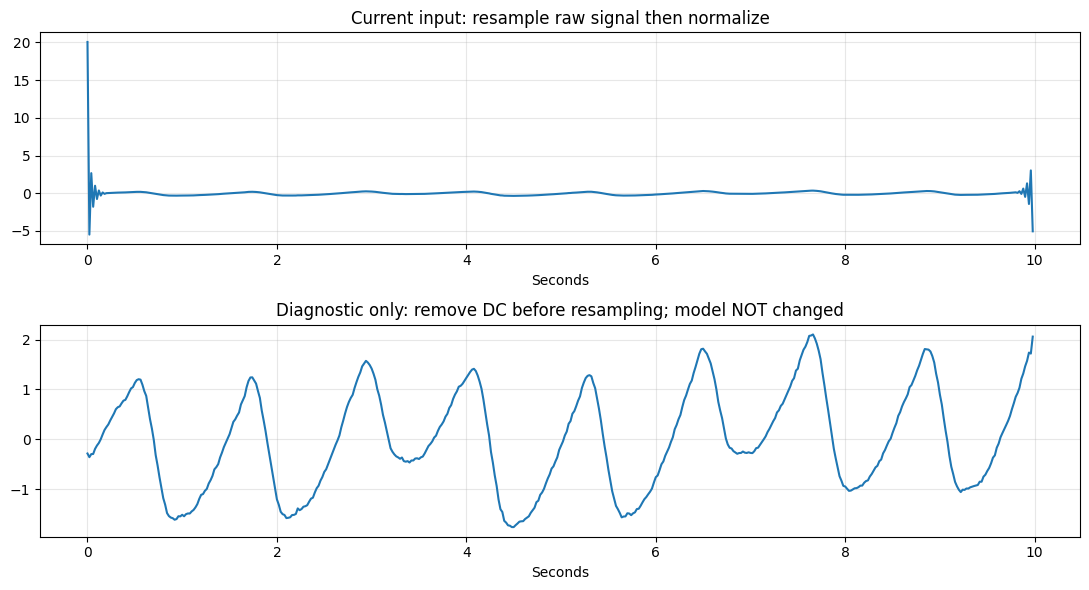

BOUNDARY_AUDIT_COMPLETE


In [ ]:
# 원본 재추출로 경계 스파이크 원인 확인 (모델/라벨 변경 없음)
import h5py, numpy as np, json, sys
from scipy.signal import resample_poly
sys.path.insert(0,str(repo/'scripts'))
from prepare_af_integrated import chars, start_time
from train_af import preprocess_window
auditdir=base/'models/provisional_exact01_v1/error_audit_v1'
audit=json.loads((auditdir/'report.json').read_text())
edgechecks=[]
for case in audit['random_example_cases']:
    person, recording=case['record'].split('_'); recording=int(recording)
    with h5py.File(base/'raw/longterm_af_v3'/f'{person}_PPG.mat') as f:
        day=chars(f[f['recording_startday'][()].ravel()[recording]])
        clock=chars(f[f['recording_starttime'][()].ravel()[recording]])
        begin=start_time(day,clock)
        lo=int(round((case['start_seconds']-begin)*100));hi=lo+1000
        ds=f[f['PPG_GREEN'][()].ravel()[recording]]
        raw=(ds[0,lo:hi] if ds.shape[0]==1 else ds[lo:hi,0]).astype(float)
    with np.load(bundle/case['shard']) as f:
        stored=f['x'][case['index']]
    original=preprocess_window(raw,100,seconds=10)
    centered=resample_poly(raw-raw.mean(),1,2)
    centered=(centered-centered.mean())/centered.std()
    edge=np.r_[np.arange(10),np.arange(490,500)]
    row={'subject':person,'outcome':case['outcome'],'record':case['record'],'raw_mean':float(raw.mean()),'raw_std':float(raw.std()),'raw_dc_to_std':float(abs(raw.mean())/raw.std()),'stored_reproduction_max_error':float(np.max(abs(stored-original))),'original_peak_index':int(np.argmax(abs(original))),'original_edge_energy_fraction':float(np.sum(original[edge]**2)/np.sum(original**2)),'centered_edge_energy_fraction':float(np.sum(centered[edge]**2)/np.sum(centered**2)),'original_peak_z':float(max(abs(original))),'centered_peak_z':float(max(abs(centered)))}
    edgechecks.append(row)
print('RAW_BOUNDARY_CHECK',json.dumps(edgechecks))
(auditdir/'raw_boundary_check.json').write_text(json.dumps(edgechecks,indent=2))
import matplotlib.pyplot as plt
fig, axes=plt.subplots(2,1,figsize=(11,6))
axes[0].plot(np.arange(500)/50,original);axes[0].set_title('Current input: resample raw signal then normalize')
axes[1].plot(np.arange(500)/50,centered);axes[1].set_title('Diagnostic only: remove DC before resampling; model NOT changed')
for ax in axes:ax.set_xlabel('Seconds');ax.grid(alpha=.3)
fig.tight_layout();fig.savefig(auditdir/'boundary_comparison.png',dpi=130);plt.show()
print('BOUNDARY_AUDIT_COMPLETE')


In [ ]:
from pathlib import Path
base=Path('/content/drive/MyDrive/Capdyssey/af_integrated')
print('RAW_DIRECTORIES',[(p.name,len(list(p.glob('*.mat')))) for p in (base/'raw').iterdir() if p.is_dir()])
print('BASELINE_SAVED', (base/'models/provisional_exact01_v1/metrics.json').exists())


RAW_DIRECTORIES [('mimic_af', 2), ('six_rhythms', 91), ('longterm_af_v3', 78)]
BASELINE_SAVED True


In [ ]:
# 전처리만 바꾼 동일 조건 재학습/평가. 기존 결과는 보존.
subprocess.run(['git','pull','--ff-only'],cwd=repo,check=True)
log_path=base/'provisional_centered_v2.log'
run_logged(['-m','unittest','discover','-s','tests','-p','test_centered_preprocessing.py'])
run_logged(['scripts/prepare_af_centered.py','--base',str(base)])
run_logged(['scripts/train_af_integrated.py','--bundle',str(base/'processed/provisional_centered_v2'),'--output',str(base/'models/provisional_centered_v2'),'--epochs','20','--provisional','--split-from',str(base/'models/provisional_exact01_v1/split.json')])
old_result=json.loads((base/'models/provisional_exact01_v1/metrics.json').read_text())
new_result=json.loads((base/'models/provisional_centered_v2/metrics.json').read_text())
comparison={'old':old_result,'centered':new_result,'same_windows_and_subject_split':True,'interpretation':'Development comparison; provisional labels unchanged; not independent external validation'}
(base/'models/provisional_centered_v2/comparison.json').write_text(json.dumps(comparison,indent=2))
print('CENTERED_COMPARISON_COMPLETE',json.dumps(comparison),flush=True)


..
----------------------------------------------------------------------
Ran 2 tests in 4.122s

OK
CENTERED longterm_wrist_v3_001_000.npz 45 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_001.npz 1037 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_002.npz 78 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_003.npz 320 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_004.npz 331 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_005.npz 15 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_006.npz 195 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_007.npz 449 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_008.npz 856 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_009.npz 328 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_010.npz 19 original_reconstruction_error 0.0
CENTERED longterm_wrist_v3_001_011.npz 260 original_reco

In [ ]:
import torch
assert torch.cuda.is_available(), 'GPU가 없어 중단합니다. CPU로 대신 실행하지 않습니다.'
print('GPU_CONFIRMED',torch.cuda.get_device_name(0))
from pathlib import Path
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
base=Path('/content/drive/MyDrive/Capdyssey/af_integrated')
print('CENTERED_DATA_READY',(base/'processed/provisional_centered_v2/manifest.json').exists())


GPU_CONFIRMED Tesla T4
Mounted at /content/drive
CENTERED_DATA_READY True


In [ ]:
# GPU 전용: 검증군 임계값 진단 + 동일 학습량의 세 자료 조합 비교
import subprocess, sys, os
repo=Path('/content/capdyssey_gpu_evidence')
if not repo.exists(): subprocess.run(['git','clone','https://github.com/dung-ho03/capdyssey.git',str(repo)],check=True)
assert torch.cuda.is_available(), 'GPU required'
def evidence_run(args):
    with (base/'gpu_source_evidence_v1.log').open('a') as log:
        p=subprocess.Popen([sys.executable,'-u',*args],cwd=repo,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,env={**os.environ,'OMP_NUM_THREADS':'2','MKL_NUM_THREADS':'2'})
        for line in p.stdout:
            print(line,end='',flush=True);log.write(line);log.flush()
        if p.wait(): raise RuntimeError('실험 오류: 위 출력 확인')
evidence_run(['-m','unittest','discover','-s','tests','-p','test_threshold_report.py'])
evidence_run(['scripts/af_gpu_evidence.py','--base',str(base)])


..
----------------------------------------------------------------------
Ran 2 tests in 0.010s

OK
EXISTING_VALIDATION_THRESHOLDS {"longterm_wrist_v3": {"metrics": {"threshold": 0.5, "n": 20417, "tp": 1228, "fn": 5189, "tn": 11631, "fp": 2369, "accuracy": 0.6298182886810011, "sensitivity": 0.1913666822502727, "specificity": 0.8307857142857142, "false_positive_rate": 0.1692142857142857, "balanced_accuracy": 0.5110761982679934, "f1": 0.24525664070301578, "roc_auc": 0.5246895801331285}, "thresholds": {"at_05": {"threshold": 0.5, "sensitivity": 0.19136668225027276, "specificity": 0.8307857142857142}, "at_sensitivity_90": {"threshold": 0.20800000000000002, "sensitivity": 0.9005765934237182, "specificity": 0.14792857142857144}, "at_specificity_80": {"threshold": 0.49, "sensitivity": 0.2250272713105813, "specificity": 0.801}}}, "mimic_perform_af": {"metrics": {"threshold": 0.5, "n": 838, "tp": 425, "fn": 53, "tn": 299, "fp": 61, "accuracy": 0.863961813842482, "sensitivity": 0.889121338912133

RuntimeError: 실험 오류: 위 출력 확인

In [ ]:
# 저장된 완료 모델을 복구하고 나머지 GPU 비교를 계속합니다.
subprocess.run(['git','pull','--ff-only'],cwd=repo,check=True)
assert torch.cuda.is_available(), 'GPU required'
evidence_run(['scripts/af_gpu_evidence.py','--base',str(base)])


EXISTING_VALIDATION_THRESHOLDS {"longterm_wrist_v3": {"metrics": {"threshold": 0.5, "n": 20417, "tp": 1228, "fn": 5189, "tn": 11631, "fp": 2369, "accuracy": 0.6298182886810011, "sensitivity": 0.1913666822502727, "specificity": 0.8307857142857142, "false_positive_rate": 0.1692142857142857, "balanced_accuracy": 0.5110761982679934, "f1": 0.24525664070301578, "roc_auc": 0.5246895801331285}, "thresholds": {"at_05": {"threshold": 0.5, "sensitivity": 0.19136668225027276, "specificity": 0.8307857142857142}, "at_sensitivity_90": {"threshold": 0.20800000000000002, "sensitivity": 0.9005765934237182, "specificity": 0.14792857142857144}, "at_specificity_80": {"threshold": 0.49, "sensitivity": 0.2250272713105813, "specificity": 0.801}}}, "mimic_perform_af": {"metrics": {"threshold": 0.5, "n": 838, "tp": 425, "fn": 53, "tn": 299, "fp": 61, "accuracy": 0.863961813842482, "sensitivity": 0.8891213389121339, "specificity": 0.8305555555555556, "false_positive_rate": 0.16944444444444445, "balanced_accuracy

In [ ]:
# 저장 결과를 다시 열어 확인하고 비교표 표시
import json, numpy as np
from IPython.display import display, HTML
folder=base/'models/gpu_source_evidence_v1'
report=json.loads((folder/'comparison.json').read_text())
protocol=json.loads((folder/'protocol.json').read_text())
print('SAVED_GPU',protocol['device'])
for group in report:
    assert (folder/group/'best_model.pt').stat().st_size>0
print('VERIFIED: 3 model checkpoints and comparison.json')
html='<h3>T4 GPU 비교 완료 — 검증군 결과</h3><p>각 자료의 특이도 약 80% 조건에서 민감도 비교<br>자료별 진단용 임계값이며 단일 배포 기준이 아닙니다.</p><table border=1 cellpadding=7><tr><th>학습 자료</th><th>MIMIC</th><th>6종 PPG</th><th>손목 PPG</th></tr>'
for group,label in [('two_sources','MIMIC+6종'),('wrist_only','손목 단독'),('three_sources','세 자료 통합')]:
    vals=[100*report[group]['by_source'][s]['thresholds']['at_specificity_80']['sensitivity'] for s in ['mimic_perform_af','six_rhythms','longterm_wrist_v3']]
    html+='<tr><td>'+label+'</td>'+''.join(f'<td>{v:.1f}%</td>' for v in vals)+'</tr>'
html+='</table><p>시험군 미사용 · 단일 seed 개발 비교 · 손목 정답은 잠정 해석</p>'
display(HTML(html))
(folder/'summary.html').write_text(html)
print('GPU_EVIDENCE_SAVED_AND_VERIFIED')


SAVED_GPU Tesla T4
VERIFIED: 3 model checkpoints and comparison.json


학습 자료,MIMIC,6종 PPG,손목 PPG
MIMIC+6종,91.6%,83.2%,14.0%
손목 단독,31.8%,2.4%,20.5%
세 자료 통합,89.7%,85.3%,23.5%


GPU_EVIDENCE_SAVED_AND_VERIFIED


In [ ]:
# PPG 리듬 특징 + 10초 전체 관계 모델: GPU 필수, 공통 임계값 검증
from pathlib import Path
import subprocess, sys, os, torch
assert torch.cuda.is_available(), 'GPU 런타임으로 연결해야 합니다. CPU 실행 금지'
print('GPU:', torch.cuda.get_device_name(0), flush=True)
base=Path('/content/drive/MyDrive/Capdyssey/af_integrated')
assert (base/'processed/provisional_centered_v2/manifest.json').exists(), 'Drive 연결을 확인하세요'
repo=Path('/content/capdyssey_gpu_evidence')
if not repo.exists(): subprocess.run(['git','clone','https://github.com/dung-ho03/capdyssey.git',str(repo)],check=True)
subprocess.run(['git','fetch','origin','main'],cwd=repo,check=True)
subprocess.run(['git','checkout','18ff062'],cwd=repo,check=True)
sys.path.insert(0,str(repo/'scripts'))
from train_af_rhythm import rhythm_features, RhythmModel, choose_threshold
import numpy as np
# 실제 학습 전 GPU 특징·형상·공통 임계값 검증
wave=torch.sin(torch.arange(500,device='cuda')*.16).repeat(4,1)
z,f,q=rhythm_features(wave)
assert torch.isfinite(f).all()
assert torch.allclose(f,rhythm_features(wave+100)[1],atol=.01)
for kind in ('features','hybrid'):
    m=RhythmModel(f.shape[1],kind).cuda()
    assert m(z,f).shape==(4,)
labels=np.array([0,0,1,1]*3); probs=np.array([.1,.2,.8,.9]*3); src=np.repeat(['a','b','c'],4)
t,score=choose_threshold(labels,probs,src)
assert score==1 and .2<t<=.8
print('GPU_SMOKE_CHECKS_OK',flush=True)
with (base/'rhythm_candidates_v1.log').open('a') as log:
    proc=subprocess.Popen([sys.executable,'-u','scripts/train_af_rhythm.py','--base',str(base)],cwd=repo,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,env={**os.environ,'OMP_NUM_THREADS':'2','MKL_NUM_THREADS':'2'})
    for line in proc.stdout:
        print(line,end='',flush=True);log.write(line);log.flush()
    assert proc.wait()==0, '실험 오류: 위 로그 확인, 완료 epoch부터 재개 가능'
print('RHYTHM_RUN_FINISHED')

GPU: Tesla T4
GPU_SMOKE_CHECKS_OK
RHYTHM_GPU_START Tesla T4 train 99777 validation 32373
RHYTHM_EPOCH features {"epoch": 1, "loss": 0.4386447743488636, "threshold": 0.652, "macro_sensitivity_at_spec80": 0.6092153934933059}
RHYTHM_EPOCH features {"epoch": 2, "loss": 0.37243143708308024, "threshold": 0.679, "macro_sensitivity_at_spec80": 0.6014924381014684}
RHYTHM_EPOCH features {"epoch": 3, "loss": 0.35634219860972516, "threshold": 0.587, "macro_sensitivity_at_spec80": 0.6382847952021468}
RHYTHM_EPOCH features {"epoch": 4, "loss": 0.34788079837867814, "threshold": 0.589, "macro_sensitivity_at_spec80": 0.6398638776505957}
RHYTHM_EPOCH features {"epoch": 5, "loss": 0.3399775243843606, "threshold": 0.544, "macro_sensitivity_at_spec80": 0.6770424405692624}
RHYTHM_EPOCH features {"epoch": 6, "loss": 0.33103927660729393, "threshold": 0.545, "macro_sensitivity_at_spec80": 0.680948684475486}
RHYTHM_EPOCH features {"epoch": 7, "loss": 0.32483686699387865, "threshold": 0.548, "macro_sensitivity_a

In [ ]:
# ===== AF_annotation 의미 검증: "윈도우 내 AF beat 비율" 가설 테스트 =====
import h5py
import numpy as np
from pathlib import Path

raw = Path('/content/drive/MyDrive/Capdyssey/af_integrated/raw/longterm_af_v3')
# 여러 값(0, 0.25, 0.5, 1)이 섞여 있던 피험자를 우선 확인 (예: 001, 006 등 이미 로그에서 본 대상)
subjects_to_check = ['001', '006', '039']

fs_ecg = 100  # signalHeader에서 실제 샘플링레이트 확인 필요시 조정
window_sec = 10

for person in subjects_to_check:
    with h5py.File(raw / f'{person}_ECG.mat') as f:
        annot = f['AF_annotation'][()].ravel()      # beat별 AF 라벨 (0~1 혼합값 포함)
        qrs_idx = f['QRSindex'][()].ravel()          # beat별 샘플 인덱스 (QRS 위치)
        rr = f['rr'][()].ravel()                      # beat별 RR 간격

    # beat 시간(초) 계산: QRS 샘플 인덱스를 샘플링레이트로 나눔
    beat_time_sec = qrs_idx[:len(annot)] / fs_ecg

    # 고유값 분포 먼저 확인
    uniq, cnt = np.unique(annot, return_counts=True)
    print(f'--- subject {person} ---')
    print('AF_annotation 고유값 분포:', dict(zip(uniq.tolist(), cnt.tolist())))

    # annot 자체가 이미 0/1이 아니라 0.25/0.5처럼 소수값을 "직접" 갖는지,
    # 아니면 우리가 임의로 10초 윈도우로 묶어야 소수값이 나오는지 둘 다 확인

    # (A) 원본 그대로 놓고, 인접한 소수값 구간이 beat-level에서 이미 존재하는지
    frac_mask = (annot > 0) & (annot < 1)
    print('beat-level에서 이미 0<val<1인 샘플 수:', frac_mask.sum(), '/', len(annot))

    # (B) 10초 윈도우로 묶어서 "포함된 beat들의 평균 AF 비율"을 직접 계산해 비교
    total_time = beat_time_sec[-1]
    n_windows = int(total_time // window_sec)
    computed_fracs = []
    for w in range(min(n_windows, 2000)):  # 앞부분 2000개 윈도우만 샘플 검증
        lo, hi = w * window_sec, (w + 1) * window_sec
        sel = (beat_time_sec >= lo) & (beat_time_sec < hi)
        if sel.sum() == 0:
            continue
        computed_fracs.append(annot[sel].mean())

    computed_fracs = np.array(computed_fracs)
    uniq2, cnt2 = np.unique(np.round(computed_fracs, 3), return_counts=True)
    print('직접 묶은 10초 윈도우의 평균값 분포(앞부분 샘플):')
    for u, c in list(zip(uniq2.tolist(), cnt2.tolist()))[:10]:
        print(f'   value={u}, count={c}')
    print()

print('VERIFICATION_COMPLETE')


--- subject 001 ---
AF_annotation 고유값 분포: {0.0: 626188, 1.0: 274232}
beat-level에서 이미 0<val<1인 샘플 수: 0 / 900420
직접 묶은 10초 윈도우의 평균값 분포(앞부분 샘플):
   value=0.0, count=1926

--- subject 006 ---
AF_annotation 고유값 분포: {0.0: 631857, 0.25: 642, 0.5: 132, 1.0: 231991}
beat-level에서 이미 0<val<1인 샘플 수: 774 / 864622
직접 묶은 10초 윈도우의 평균값 분포(앞부분 샘플):
   value=0.0, count=1997

--- subject 039 ---
AF_annotation 고유값 분포: {0.0: 390024, 0.25: 88, 0.5: 28, 1.0: 129136}
beat-level에서 이미 0<val<1인 샘플 수: 116 / 519276
직접 묶은 10초 윈도우의 평균값 분포(앞부분 샘플):
   value=0.0, count=1998

VERIFICATION_COMPLETE


In [ ]:
import h5py
import numpy as np
from pathlib import Path

raw = Path('/content/drive/MyDrive/Capdyssey/af_integrated/raw/longterm_af_v3')

for person in ['006', '039']:
    with h5py.File(raw / f'{person}_ECG.mat') as f:
        annot = f['AF_annotation'][()].ravel()

    frac_idx = np.where((annot > 0) & (annot < 1))[0]
    print(f'--- subject {person}: 소수값 beat {len(frac_idx)}개 ---')

    # 소수값 beat 주변(앞뒤 3개씩)의 라벨 시퀀스를 샘플로 출력
    for i in frac_idx[:10]:
        lo, hi = max(0, i-3), min(len(annot), i+4)
        print(f'  idx={i}  value={annot[i]}  주변시퀀스={annot[lo:hi]}')

    # 소수값 beat 중 '앞뒤가 서로 다른 값(0/1)으로 갈리는' 비율 계산
    is_transition = 0
    for i in frac_idx:
        lo, hi = max(0, i-1), min(len(annot)-1, i+1)
        if annot[lo] != annot[hi]:
            is_transition += 1
    print(f'  → 앞뒤 값이 서로 다른(=전환 경계로 보이는) 비율: {is_transition}/{len(frac_idx)} = {is_transition/len(frac_idx):.1%}')
    print()


--- subject 006: 소수값 beat 774개 ---
  idx=50175  value=0.25  주변시퀀스=[0.   0.   0.   0.25 0.25 0.25 0.25]
  idx=50176  value=0.25  주변시퀀스=[0.   0.   0.25 0.25 0.25 0.25 0.25]
  idx=50177  value=0.25  주변시퀀스=[0.   0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50178  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50179  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50180  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50181  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50182  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50183  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  idx=50184  value=0.25  주변시퀀스=[0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  → 앞뒤 값이 서로 다른(=전환 경계로 보이는) 비율: 166/774 = 21.4%

--- subject 039: 소수값 beat 116개 ---
  idx=8272  value=0.25  주변시퀀스=[0.   0.   0.   0.25 0.   0.   0.  ]
  idx=15927  value=0.25  주변시퀀스=[0.   0.   0.   0.25 0.25 0.25 0.25]
  idx=15928  value=0.25  주변시퀀스=[0.   0.   0.25 0.25 0.25 0.25 0.2

In [ ]:
import h5py
import numpy as np
from pathlib import Path

raw = Path('/content/drive/MyDrive/Capdyssey/af_integrated/raw/longterm_af_v3')

def run_lengths(mask):
    """True인 구간들의 연속 길이 리스트 반환"""
    runs = []
    count = 0
    for v in mask:
        if v:
            count += 1
        else:
            if count > 0:
                runs.append(count)
            count = 0
    if count > 0:
        runs.append(count)
    return runs

for person in ['006', '039']:
    with h5py.File(raw / f'{person}_ECG.mat') as f:
        annot = f['AF_annotation'][()].ravel()

    for val in [0.25, 0.5]:
        mask = (annot == val)
        if mask.sum() == 0:
            continue
        runs = run_lengths(mask)
        print(f'subject {person}, value={val}: 총 {mask.sum()} beat, '
              f'구간(run) 개수={len(runs)}, 길이분포(beat)={sorted(runs, reverse=True)[:15]}')

    print()


subject 006, value=0.25: 총 642 beat, 구간(run) 개수=76, 길이분포(beat)=[92, 30, 27, 26, 22, 18, 17, 15, 14, 14, 13, 13, 12, 12, 11]
subject 006, value=0.5: 총 132 beat, 구간(run) 개수=7, 길이분포(beat)=[99, 10, 7, 7, 4, 3, 2]

subject 039, value=0.25: 총 88 beat, 구간(run) 개수=23, 길이분포(beat)=[18, 8, 7, 7, 6, 5, 4, 3, 3, 3, 3, 3, 3, 2, 2]
subject 039, value=0.5: 총 28 beat, 구간(run) 개수=9, 길이분포(beat)=[8, 4, 3, 3, 2, 2, 2, 2, 2]

